# Exercise 4 — E-Commerce Text & Quantitative Analytics

**Author:** Mayank Mishra  
**Date:** 21 November 2026  
**Environment:** Python 3.12, pandas, Matplotlib, WordCloud

## Objective

Analyse Flipkart product reviews by cleaning the dataset, converting rating and
price fields to numeric values, summarising products, and visualising the most
frequent terms in customer review summaries with a word cloud.

## Dataset

`dataset/flipkart_reviews.csv` — Flipkart product reviews. The public copy used
here was obtained from the Hugging Face dataset
[`ml-hub/flipkart-reviews`](https://huggingface.co/datasets/ml-hub/flipkart-reviews),
which mirrors the Flipkart review data used in the exercise.

Actual columns in the file:

`product_name`, `product_price`, `Rate`, `Review`, `Summary`, `Sentiment`

The notebook renames `product_name` to `Product_name` and `product_price` to
`Price` so the analysis follows the exercise specification while remaining
faithful to the source file.

## Expected outputs

- `outputs/Exercise4/cleaned_reviews.csv`
- `outputs/Exercise4/product_summary.csv`
- `outputs/Exercise4/wordcloud.png`
- `outputs/Exercise4/rating_distribution.png`
- `outputs/Exercise4/top_products.png`

## 1. Import libraries and define paths

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from wordcloud import STOPWORDS, WordCloud

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "dataset" / "flipkart_reviews.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "Exercise4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset     : {DATA_PATH}")
print(f"Output folder: {OUTPUT_DIR}")
print(f"File exists : {DATA_PATH.exists()}")

Dataset     : C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\dataset\flipkart_reviews.csv
Output folder: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise4
File exists : True


## 2. Load the dataset and inspect its structure

In [2]:
df_raw = pd.read_csv(DATA_PATH)

print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Columns  : {df_raw.columns.tolist()}")
df_raw.info()

Raw shape: 205,052 rows x 6 columns
Columns  : ['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']
<class 'pandas.DataFrame'>
RangeIndex: 205052 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   product_name   205052 non-null  str  
 1   product_price  205052 non-null  str  
 2   Rate           205052 non-null  str  
 3   Review         180388 non-null  str  
 4   Summary        205041 non-null  str  
 5   Sentiment      205052 non-null  str  
dtypes: str(6)
memory usage: 9.4 MB


In [3]:
df_raw.head(3)

,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive


## 3. Data-quality assessment

In [4]:
quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_values": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(),
})
quality["missing_percent"] = (
    quality["missing_values"] / len(df_raw) * 100
).round(2)
quality

,dtype,missing_values,unique_values,missing_percent
product_name,str,0,958,0.00
product_price,str,0,525,0.00
Rate,str,0,8,0.00
Review,str,24664,1324,12.03
Summary,str,11,92923,0.01
Sentiment,str,0,3,0.00


In [5]:
print(f"Exact duplicate rows: {df_raw.duplicated().sum():,}")
print("\nRating values before cleaning:")
print(df_raw["Rate"].value_counts(dropna=False).head(10).to_string())

Exact duplicate rows: 34,375

Rating values before cleaning:
Rate
5                                                                    118765
4                                                                     41894
1                                                                     21300
3                                                                     16599
2                                                                      6491
Pigeon Favourite Electric Kettle??????(1.5 L, Silver, Black)              1
Bajaj DX 2 L/W Dry Iron                                                   1
Nova Plus Amaze NI 10 1100 W Dry Iron?ÃÂ¿?ÃÂ¿(Grey & Turquoise)         1


## 4. Clean rating, price, and text fields

In [6]:
df = df_raw.copy()

# Use the exercise's canonical names while preserving the source values.
df = df.rename(columns={
    "product_name": "Product_name",
    "product_price": "Price",
})

# Convert ratings to numbers; non-numeric rows become NaN.
df["Rate"] = pd.to_numeric(df["Rate"], errors="coerce")

# Remove currency symbols, commas, and other non-numeric characters.
df["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce",
)

rows_before = len(df)

# Keep only valid ratings (1–5) and complete essential fields.
df = df[df["Rate"].between(1, 5)]
df = df.dropna(subset=["Product_name", "Rate", "Price"])

# Remove exact duplicate records.
df = df.drop_duplicates()

# Normalise text fields.
df["Product_name"] = df["Product_name"].astype(str).str.strip()
df["Summary"] = df["Summary"].fillna("").astype(str).str.strip()
df["Review"] = df["Review"].fillna("").astype(str).str.strip()
df["Sentiment"] = (
    df["Sentiment"].fillna("unknown").astype(str).str.strip().str.lower()
)
df["Review_length"] = df["Review"].str.split().str.len()
df["Rate"] = df["Rate"].astype("int8")

df = df.reset_index(drop=True)

print(f"Rows before cleaning : {rows_before:,}")
print(f"Rows after cleaning  : {len(df):,}")
print(f"Rows removed         : {rows_before - len(df):,}")
print(f"Products             : {df['Product_name'].nunique():,}")
print(f"Rating range         : {df['Rate'].min()} to {df['Rate'].max()}")
print(f"Price range          : {df['Price'].min():,.0f} to {df['Price'].max():,.0f}")
df.head()

Rows before cleaning : 205,052
Rows after cleaning  : 170,674
Rows removed         : 34,378
Products             : 958
Rating range         : 1 to 5
Price range          : 59 to 86,990


,Product_name,Price,Rate,Review,Summary,Sentiment,Review_length
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive,1
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive,1
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive,1
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative,2
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral,1


## 5. Group by product and calculate mean rating and mean price

In [7]:
items = (
    df.groupby("Product_name", as_index=False)
      .agg(
          mean_rating=("Rate", "mean"),
          mean_price=("Price", "mean"),
          review_count=("Rate", "size"),
      )
      .sort_values(["review_count", "mean_rating"], ascending=[False, False])
      .reset_index(drop=True)
)

items["mean_rating"] = items["mean_rating"].round(2)
items["mean_price"] = items["mean_price"].round(2)

summary_path = OUTPUT_DIR / "product_summary.csv"
items.to_csv(summary_path, index=False)

print(f"Product summary shape: {items.shape}")
print(f"Saved: {summary_path}")
items.head(10)

Product summary shape: (958, 4)
Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise4\product_summary.csv


,Product_name,mean_rating,mean_price,review_count
0,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,4.27,1299.0,4362
1,Lakm?? Eyeconic Kajal Twin Pack??????????(Deep...,4.48,218.0,2805
2,Mi 5A 80 cm (32 inch) HD Ready LED Smart Andro...,4.13,13999.0,2122
3,Singer FM 1409 Electric Sewing MachineÐÒ?ÐÓ...,4.32,8499.0,1743
4,"Canon EOS 3000D DSLR Camera 1 Camera Body, 18 ...",4.45,30999.0,1646
5,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,4.34,1299.0,1642
6,NIVIA Storm Football - Size: 5ÐÓ®ÐÂ ÐÓ®ÐÂ ...,4.04,429.0,1613
7,"POCO C31 (Royal Blue, 64 GB)?ÐÒÐÒ?ÐÒÐÒ...",3.87,7499.0,1569
8,DOMS Pencil Smart Kit,4.70,449.0,1545
9,Google Nest Mini (2nd Gen) with Google Assista...,3.97,3499.0,1509


## 6. Generate the word cloud from review summaries

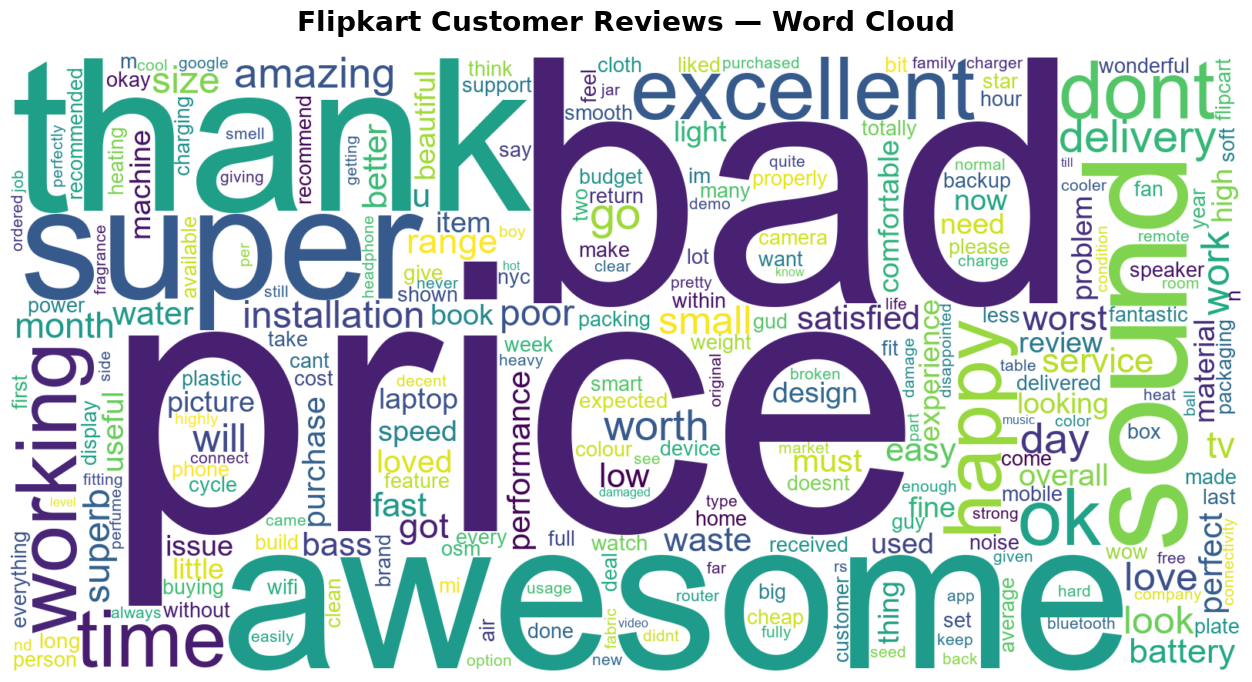

Words in vocabulary: 250
Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise4\wordcloud.png


In [8]:
summary_text = " ".join(df["Summary"].dropna().astype(str))

# Keep alphabetic words and remove common English stop words.
summary_text = re.sub(r"http\S+", " ", summary_text)
summary_text = re.sub(r"[^A-Za-z\s]", " ", summary_text)
summary_text = re.sub(r"\s+", " ", summary_text).strip().lower()

extra_stopwords = {
    "flipkart", "product", "products", "good", "nice", "best", "great",
    "very", "really", "quality", "value", "money", "buy", "bought",
    "use", "using", "one", "also", "would", "could", "much", "well",
    "even", "get",
}
stopwords = set(STOPWORDS) | extra_stopwords

font_path = r"C:\Windows\Fonts\arial.ttf"
font_path = font_path if Path(font_path).exists() else None

wordcloud = WordCloud(
    width=1600,
    height=800,
    background_color="white",
    colormap="viridis",
    max_words=250,
    stopwords=stopwords,
    collocations=False,
    font_path=font_path,
    random_state=42,
).generate(summary_text)

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(wordcloud, interpolation="bilinear")
ax.axis("off")
ax.set_title(
    "Flipkart Customer Reviews — Word Cloud",
    fontsize=20,
    fontweight="bold",
    pad=18,
)

wordcloud_path = OUTPUT_DIR / "wordcloud.png"
fig.savefig(wordcloud_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Words in vocabulary: {len(wordcloud.words_):,}")
print(f"Saved: {wordcloud_path}")

## 7. Additional quantitative visualisations

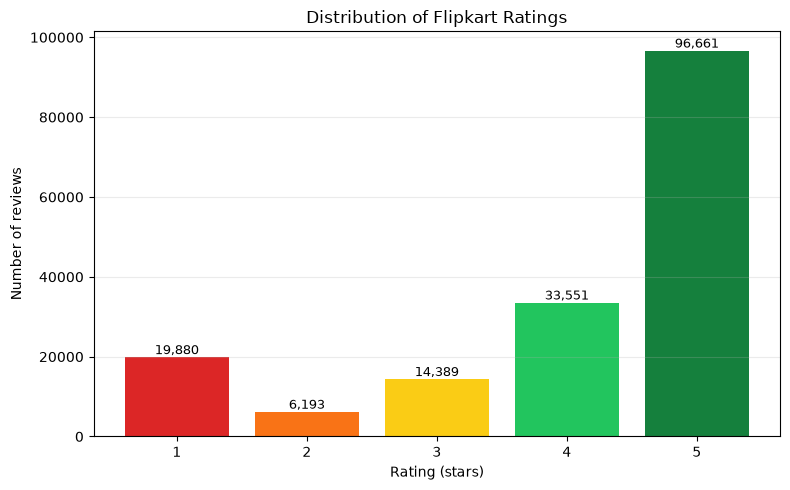

Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise4\rating_distribution.png


In [9]:
rating_counts = df["Rate"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    rating_counts.index.astype(str),
    rating_counts.values,
    color=["#dc2626", "#f97316", "#facc15", "#22c55e", "#15803d"],
)
ax.set_xlabel("Rating (stars)")
ax.set_ylabel("Number of reviews")
ax.set_title("Distribution of Flipkart Ratings")
ax.grid(axis="y", alpha=0.25)

for bar, count in zip(bars, rating_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
rating_path = OUTPUT_DIR / "rating_distribution.png"
fig.savefig(rating_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {rating_path}")

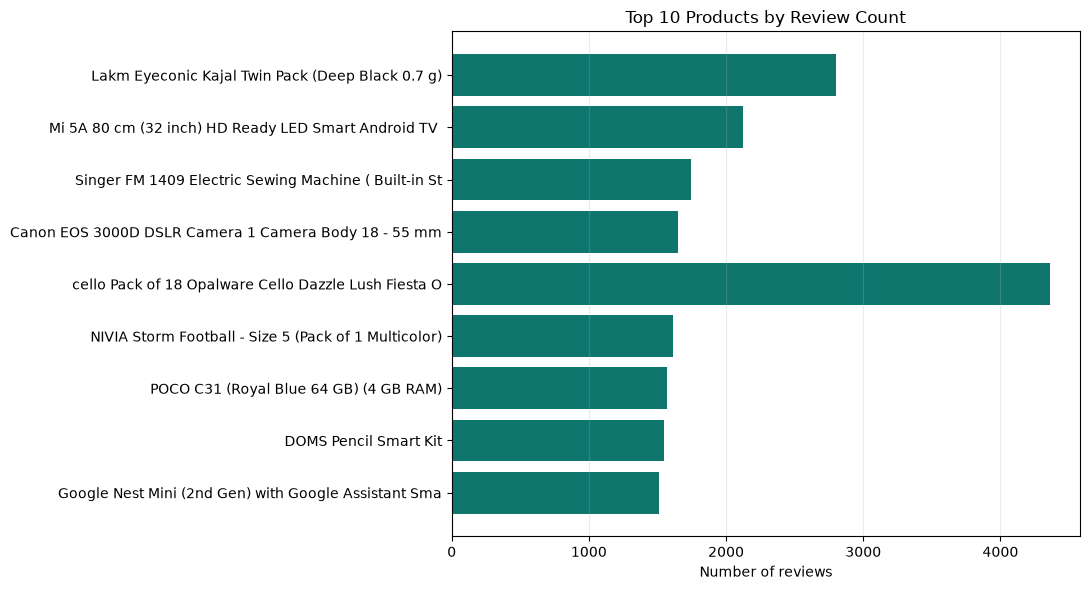

Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise4\top_products.png


In [10]:
top_products = items.head(10).sort_values("review_count")
labels = (
    top_products["Product_name"]
    .str.replace(r"[^A-Za-z0-9&+./()\- ]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.slice(0, 52)
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(labels, top_products["review_count"], color="#0f766e")
ax.set_xlabel("Number of reviews")
ax.set_title("Top 10 Products by Review Count")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
top_products_path = OUTPUT_DIR / "top_products.png"
fig.savefig(top_products_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {top_products_path}")

## 8. Save the cleaned review dataset

In [11]:
cleaned_path = OUTPUT_DIR / "cleaned_reviews.csv"
df.to_csv(cleaned_path, index=False, encoding="utf-8")

print(f"Saved: {cleaned_path}")
print(f"Rows : {len(df):,}")
print(f"Size : {cleaned_path.stat().st_size:,} bytes")

Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise4\cleaned_reviews.csv
Rows : 170,674
Size : 29,431,798 bytes


## Conclusion

- The raw Flipkart file contained 205,052 rows and six columns. Ratings and
  prices were stored as text, and the file included three malformed records,
  missing summaries/reviews, and exact duplicate rows.
- After converting `Rate` and `Price` to numeric values, keeping ratings from
  1 to 5, dropping incomplete essential fields, and removing exact duplicates,
  the cleaned dataset was saved as `cleaned_reviews.csv`.
- Grouping by `Product_name` produced the `items` DataFrame with mean rating,
  mean price, and review count for each product. It was exported as
  `product_summary.csv`.
- The word cloud highlights the most frequent terms in customer summaries,
  while the rating and top-product charts add quantitative context.
- The notebook prints the exact cleaned row count and product count when run,
  so the figures above can be checked against the generated outputs.

**Deliverables produced:** `cleaned_reviews.csv`, `product_summary.csv`,
`wordcloud.png`, `rating_distribution.png`, and `top_products.png`.